<a href="https://colab.research.google.com/github/pushkarkn/Multimodal-Cognitive-Workload-Classification-/blob/main/Multimodal_Cognitive_Workload.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
!pip install openneuro-py
!pip install mne
import openneuro as on
dataset_id = 'ds007169'
on.download(dataset=dataset_id, target_dir='./dataset_bids')


🌍 Preparing to download ds007169 …
🔄 Request timed out while retrieving metadata for ds007169, retrying (5 retries remain, backing off 0.5s) …
🔄 Request timed out while retrieving metadata for ds007169, retrying (4 retries remain, backing off 1.0s) …
📥 Checking 225 files, downloading as needed (5 concurrent downloads). 


Output()

✅ Finished downloading ds007169 (downloaded 0 files and 0 B).


In [15]:
import os
dataset_path = 'dataset_bids'

files = os.listdir(dataset_path)

print(*files, sep="\n")


sub-005
.bidsignore
sub-010
sub-019
README
sub-006
task-nback_events.json
sub-018
sub-012
sub-020
sub-008
task-nback_eeg.json
sub-016
dataset_description.json
CHANGES
sub-015
sub-007
datacite.yml
sub-004
sub-002
sub-014
sub-011
participants.json
sub-001
participants.tsv
sub-003
sourcedata
sub-009


In [16]:
import os
import glob
import pandas as pd
import json

# Define the root dataset directory (adjust if your folder has a specific name)
dataset_dir = 'dataset_bids'

print("="*60)
print("DATASET OVERVIEW & CONTENTS REPORT")
print("="*60)

# --- 1. Top-Level Dataset Descriptions ---
print("\n[1] PROJECT-LEVEL DOCUMENTATION")
print("-" * 40)

# Read BIDS Dataset Description json
desc_path = glob.glob(os.path.join(dataset_dir, '**/dataset_description.json'), recursive=True)
if desc_path:
    with open(desc_path[0], 'r') as f:
        print("📝 dataset_description.json Details:")
        print(json.dumps(json.load(f), indent=2))
else:
    print("dataset_description.json not found.")

# Read README file
readme_path = glob.glob(os.path.join(dataset_dir, '**/README*'), recursive=True)
if readme_path:
    with open(readme_path[0], 'r') as f:
        print("\n README Summary:")
        # Print first 20 lines to keep it clean
        lines = f.readlines()
        print("".join(lines[:20]))
        if len(lines) > 20: print("... [truncated]")

# --- 2. Participants Demographics & Overview ---
print("\n[2] COHORT & PARTICIPANT METRICS")
print("-" * 40)
part_path = glob.glob(os.path.join(dataset_dir, '**/participants.tsv'), recursive=True)
if part_path:
    part_df = pd.read_csv(part_path[0], sep='\t')
    print(f"Total Participants Loaded: {len(part_df)}")
    print("\n Columns & Sample Data available for Subjects:")
    print(part_df.info())
    print("\n First 5 Subjects Snapshot:")
    print(part_df.head())
else:
    print(" participants.tsv not found.")

# --- 3. Directory File-Type Structural Scan ---
print("\n[3] SCANNING DATASET STRUCTURE & CHANNELS")
print("-" * 40)

# Find samples of the primary raw behavioral, eeg, and pupil data formats
tsv_files = glob.glob(os.path.join(dataset_dir, '**/*_events.tsv'), recursive=True)
json_metadata = glob.glob(os.path.join(dataset_dir, '**/*_eeg.json'), recursive=True)
vhdr_files = glob.glob(os.path.join(dataset_dir, '**/*.vhdr'), recursive=True)

# Peek into behavioral event logs
if tsv_files:
    print(f" Found {len(tsv_files)} behavioral/event files. Example data structure (`*_events.tsv`):")
    sample_ev = pd.read_csv(tsv_files[0], sep='\t')
    print(f"Available Columns: {list(sample_ev.columns)}")
    print(sample_ev.head(3))
    print()

# Peek into EEG device and task metadata
if json_metadata:
    print(" Technical EEG & Task Metadata Schema Example (`*_eeg.json`):")
    with open(json_metadata[0], 'r') as f:
        # Print key configuration aspects
        meta = json.load(f)
        for key in ['TaskName', 'SamplingFrequency', 'EEGChannelCount', 'EOGChannelCount', 'ECGChannelCount', 'PowerLineFrequency'][:len(meta)]:
            if key in meta: print(f"   • {key}: {meta[key]}")

# Count general physical data assets
all_files = glob.glob(os.path.join(dataset_dir, '**/*'), recursive=True)
extensions = [os.path.splitext(f)[1] for f in all_files if os.path.isfile(f)]
ext_counts = pd.Series(extensions).value_counts()

print("\n Overall File Type Counts Across Dataset:")
for ext, count in ext_counts.items():
    if ext: print(f"   • {ext}: {count} files")


DATASET OVERVIEW & CONTENTS REPORT

[1] PROJECT-LEVEL DOCUMENTATION
----------------------------------------
📝 dataset_description.json Details:
{
  "Name": "Multimodal Cognitive Workload n-back Task, 4 Difficulties",
  "BIDSVersion": "1.9.0",
  "DatasetType": "raw",
  "License": "CC0",
  "Authors": [
    "Matthew Barras",
    "Liam Booth"
  ],
  "GeneratedBy": [
    {
      "Name": "MNE-BIDS",
      "Version": "0.18.0",
      "CodeURL": "https://mne.tools/mne-bids/"
    }
  ],
  "SourceDatasets": [
    {
      "Directory": "sourcedata",
      "Version": "1.0.0"
    }
  ],
  "DatasetDOI": "doi:10.18112/openneuro.ds007169.v1.0.5"
}

 README Summary:
This dataset was generated from LSL/XDF recordings. Converted to BIDS with instructions and code [presented here](https://github.com/LMBooth/QT-nback_study/tree/main/conversion_package)

- Original recordings are stored under sourcedata/xdf/ as .xdf files (non-BIDS).
- EEG was converted to BrainVision format (.vhdr/.eeg/.vmrk) under each sub

In [17]:
import pandas as pd
import glob
import os
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Load participants and find who to include
participants_df = pd.read_csv('dataset_bids/participants.tsv', sep='\t')
included_subs = participants_df[participants_df['analysis_included'] == True]['participant_id'].tolist()
print(f"Cleaned Cohort: Proceeding with {len(included_subs)} valid participants.")

# 2. Gather and clean event data
all_trials = []
event_files = glob.glob('dataset_bids/**/*events.tsv', recursive=True)

for file in event_files:
    # Extract subject ID from path (e.g., 'sub-001')
    sub_id = os.path.basename(file).split('_')[0]

    # Skip excluded subjects
    if sub_id not in included_subs:
        continue

    df = pd.read_csv(file, sep='\t')

    # Filter: Keep rows where an n-back level exists (removes dropped_samples rows)
    # Also filter out practice/tutorial blocks if you only want the main experiment
    df_cleaned = df[df['nback_level'].notna() & (df['istutorial'] == False)].copy()

    # Add metadata columns for mapping back
    df_cleaned['subject_id'] = sub_id

    all_trials.append(df_cleaned)

# --- Add this debug block right before pd.concat ---
print(f"Number of files successfully loaded: {len(all_trials)}")

if not all_trials:
    raise ValueError("No data frames were loaded. Check your file paths or search patterns.")

# Create the master behavioral dataframe
behavior_df = pd.concat(all_trials, ignore_index=True)


# Ensure columns are treated as correct types
behavior_df['nback_level'] = behavior_df['nback_level'].astype(int)
behavior_df['response_accuracy'] = behavior_df['response_accuracy'].astype(int)

print(f" Extracted {len(behavior_df)} total trial observations across the cohort.")


Cleaned Cohort: Proceeding with 18 valid participants.
Number of files successfully loaded: 18
 Extracted 7200 total trial observations across the cohort.


In [18]:
# 1. Did we successfully remove tutorial/practice trials?
print("Remaining tutorial trials:", (behavior_df['istutorial'] == True).sum())

# 2. Did we successfully remove missing N-back rows?
print("Remaining missing N-back rows:", behavior_df['nback_level'].isna().sum())

# 3. Did we successfully exclude bad participants?
# (Check if any participant NOT in your approved list sneaked in)
unapproved_found = behavior_df[~behavior_df['subject_id'].isin(included_subs)]
print("Trials from unapproved participants:", len(unapproved_found))


print("\n--- Final behavior_df Summary ---")
behavior_df.info()
print("\nColumns in behavior_df:", behavior_df.columns.tolist())
print("Unique N-back levels left:", behavior_df['nback_level'].unique())
print("Unique Accuracy scores left:", behavior_df['response_accuracy'].unique())
print("Shape of behavior_df:", behavior_df.shape)


Remaining tutorial trials: 0
Remaining missing N-back rows: 0
Trials from unapproved participants: 0

--- Final behavior_df Summary ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7200 entries, 0 to 7199
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   onset              7200 non-null   float64
 1   duration           7200 non-null   float64
 2   trial_type         7200 non-null   object 
 3   timestamp_lsl      7200 non-null   float64
 4   marker             7200 non-null   object 
 5   response_accuracy  7200 non-null   int64  
 6   nback_level        7200 non-null   int64  
 7   key_press          7200 non-null   object 
 8   matched            7200 non-null   object 
 9   outcome            7200 non-null   object 
 10  istutorial         7200 non-null   object 
 11  dropped_samples    0 non-null      float64
 12  marker_stream      7200 non-null   object 
 13  subject_id         7200 non-null

In [21]:
import mne
import numpy as np
import pandas as pd
from pathlib import Path
from mne.time_frequency import psd_array_welch

# 1. Setup paths
base_dir = Path(dataset_path)
subject = "sub-001"
vhdr_file = base_dir / subject / "eeg" / f"{subject}_task-nback_eeg.vhdr"

# 2. Load and Filter
raw = mne.io.read_raw_brainvision(vhdr_file, preload=True, verbose=False)
raw.filter(1., 40., fir_design='firwin', verbose=False)

# 3. Get the behavior data for THIS subject only
sub_df = behavior_df[behavior_df['subject_id'] == subject].copy()

# Filter out error trials (only keep accurate responses)
sub_df = sub_df[sub_df['response_accuracy'] == 1].copy()

# 4. Create events array manually from the dataframe
sfreq = raw.info['sfreq']
event_ids = sub_df['nback_level'].values
samples = (sub_df['onset'].values * sfreq).astype(int)

# Map 1,2,3,4 to MNE event IDs
mne_events = np.column_stack([samples, np.zeros(len(samples), dtype=int), event_ids])

# Define the correct event_id dictionary for MNE
unique_events = np.unique(event_ids)
event_id_dict = {f"{level}-back": int(level) for level in unique_events}

# 5. Epoch the data (0 to 1 second after stimulus) without baseline correction to avoid errors
tmin, tmax = 0., 1.
epochs = mne.Epochs(
    raw, mne_events, event_id=event_id_dict, tmin=tmin, tmax=tmax,
    baseline=None, preload=True, verbose=False
)

# 6. Extract Theta (Fz) and Alpha (Pz) Power
# We use n_fft=128 (less than epoch length of 251) to avoid ValueError
theta_psds, freqs = psd_array_welch(
    epochs.get_data(picks=['Fz']), sfreq=sfreq,
    fmin=4, fmax=8, n_fft=128, verbose=False
)
alpha_psds, freqs = psd_array_welch(
    epochs.get_data(picks=['Pz']), sfreq=sfreq,
    fmin=8, fmax=12, n_fft=128, verbose=False
)

# Average across the frequency bins to get a single power value per trial
theta_power = theta_psds.mean(axis=-1).squeeze()
if theta_power.ndim == 0:
    theta_power = np.array([theta_power])

alpha_power = alpha_psds.mean(axis=-1).squeeze()
if alpha_power.ndim == 0:
    alpha_power = np.array([alpha_power])

theta_alpha_ratio = theta_power / alpha_power

# 7. Put it all in a clean dataframe!
features_df = pd.DataFrame({
    'subject_id': subject,
    'nback_level': epochs.events[:, -1],
    'theta_power': theta_power,
    'alpha_power': alpha_power,
    'theta_alpha_ratio': theta_alpha_ratio
})

print(f"Extracted features for {len(features_df)} valid trials.")
display(features_df.head())

Extracted features for 236 valid trials.


,subject_id,nback_level,theta_power,alpha_power,theta_alpha_ratio
0,sub-001,1,59.972708,1.186124,50.561929
1,sub-001,1,5.440624,3.731521,1.458018
2,sub-001,1,37.267944,1.342921,27.751407
3,sub-001,1,6.750582,1.732386,3.896697
4,sub-001,1,3.004934,9.390695,0.319991


In [22]:
import mne
import numpy as np
import pandas as pd
from pathlib import Path
from mne.time_frequency import psd_array_welch
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline

base_dir = Path(dataset_path)
all_subject_features = []

print("Starting feature extraction across all included subjects...")

for subject in included_subs:
    try:
        vhdr_file = base_dir / subject / "eeg" / f"{subject}_task-nback_eeg.vhdr"
        if not vhdr_file.exists():
            continue

        # Load & filter
        raw = mne.io.read_raw_brainvision(vhdr_file, preload=True, verbose=False)
        raw.filter(1., 40., fir_design='firwin', verbose=False)

        # Filter behavioral data
        sub_df = behavior_df[behavior_df['subject_id'] == subject].copy()
        sub_df = sub_df[sub_df['response_accuracy'] == 1].copy()

        if len(sub_df) == 0:
            continue

        # Events mapping
        sfreq = raw.info['sfreq']
        event_ids = sub_df['nback_level'].values
        samples = (sub_df['onset'].values * sfreq).astype(int)

        mne_events = np.column_stack([samples, np.zeros(len(samples), dtype=int), event_ids])
        unique_events = np.unique(event_ids)
        event_id_dict = {f"{level}-back": int(level) for level in unique_events}

        # Epochs
        epochs = mne.Epochs(
            raw, mne_events, event_id=event_id_dict, tmin=0., tmax=1.,
            baseline=None, preload=True, verbose=False
        )

        # PSD
        theta_psds, _ = psd_array_welch(epochs.get_data(picks=['Fz']), sfreq=sfreq, fmin=4, fmax=8, n_fft=128, verbose=False)
        alpha_psds, _ = psd_array_welch(epochs.get_data(picks=['Pz']), sfreq=sfreq, fmin=8, fmax=12, n_fft=128, verbose=False)

        theta_power = theta_psds.mean(axis=-1).squeeze()
        alpha_power = alpha_psds.mean(axis=-1).squeeze()

        # Handle single epoch dimensions safely
        if theta_power.ndim == 0: theta_power = np.array([theta_power])
        if alpha_power.ndim == 0: alpha_power = np.array([alpha_power])

        theta_alpha_ratio = theta_power / alpha_power

        sub_features = pd.DataFrame({
            'subject_id': subject,
            'nback_level': epochs.events[:, -1],
            'theta_power': theta_power,
            'alpha_power': alpha_power,
            'theta_alpha_ratio': theta_alpha_ratio
        })

        all_subject_features.append(sub_features)
        print(f"  Successfully processed {subject}: {len(sub_features)} trials")
    except Exception as e:
        print(f"  Error processing {subject}: {e}")

# Combine everything into one master features dataframe
all_features_df = pd.concat(all_subject_features, ignore_index=True)
print(f"\nDone! Extracted total of {len(all_features_df)} trials across all subjects.")
display(all_features_df.head())

Starting feature extraction across all included subjects...
  Successfully processed sub-001: 236 trials
  Successfully processed sub-002: 256 trials
  Successfully processed sub-003: 232 trials
  Successfully processed sub-004: 243 trials
  Successfully processed sub-005: 252 trials
  Successfully processed sub-006: 263 trials
  Successfully processed sub-007: 258 trials
  Successfully processed sub-008: 249 trials
  Successfully processed sub-009: 260 trials
  Successfully processed sub-010: 243 trials
  Successfully processed sub-011: 232 trials
  Successfully processed sub-012: 255 trials
  Successfully processed sub-014: 246 trials
  Successfully processed sub-015: 252 trials
  Successfully processed sub-016: 237 trials
  Successfully processed sub-018: 239 trials
  Successfully processed sub-019: 259 trials
  Successfully processed sub-020: 265 trials

Done! Extracted total of 4477 trials across all subjects.


,subject_id,nback_level,theta_power,alpha_power,theta_alpha_ratio
0,sub-001,1,59.972708,1.186124,50.561929
1,sub-001,1,5.440624,3.731521,1.458018
2,sub-001,1,37.267944,1.342921,27.751407
3,sub-001,1,6.750582,1.732386,3.896697
4,sub-001,1,3.004934,9.390695,0.319991


In [23]:
# Prepare dataset for binary classification: Low Load (1-back) vs. High Load (4-back)
binary_df = all_features_df[all_features_df['nback_level'].isin([1, 4])].copy()

# Define Features (X) and Labels (y)
X = binary_df[['theta_power', 'alpha_power', 'theta_alpha_ratio']].values
y = binary_df['nback_level'].map({1: 0, 4: 1}).values # Map 1-back to 0 (Low), 4-back to 1 (High)

print(f"Dataset ready. Total sample size for Low (1) vs. High (4) workload: {len(binary_df)}")
print(f"Class distribution: Low={np.sum(y==0)}, High={np.sum(y==1)}")

# Set up classification pipeline (standardize features and train SVM)
clf_pipeline = make_pipeline(StandardScaler(), SVC(kernel='linear', C=1.0))

# Evaluate with Stratified 5-Fold Cross Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(clf_pipeline, X, y, cv=cv, scoring='accuracy')

print("\n--- Classifier Evaluation Results (5-Fold CV) ---")
print(f"Fold Accuracies: {scores}")
print(f"Mean Accuracy: {scores.mean():.4f} (+/- {scores.std():.4f})")

Dataset ready. Total sample size for Low (1) vs. High (4) workload: 2035
Class distribution: Low=783, High=1252

--- Classifier Evaluation Results (5-Fold CV) ---
Fold Accuracies: [0.61425061 0.61425061 0.61425061 0.61670762 0.61670762]
Mean Accuracy: 0.6152 (+/- 0.0012)


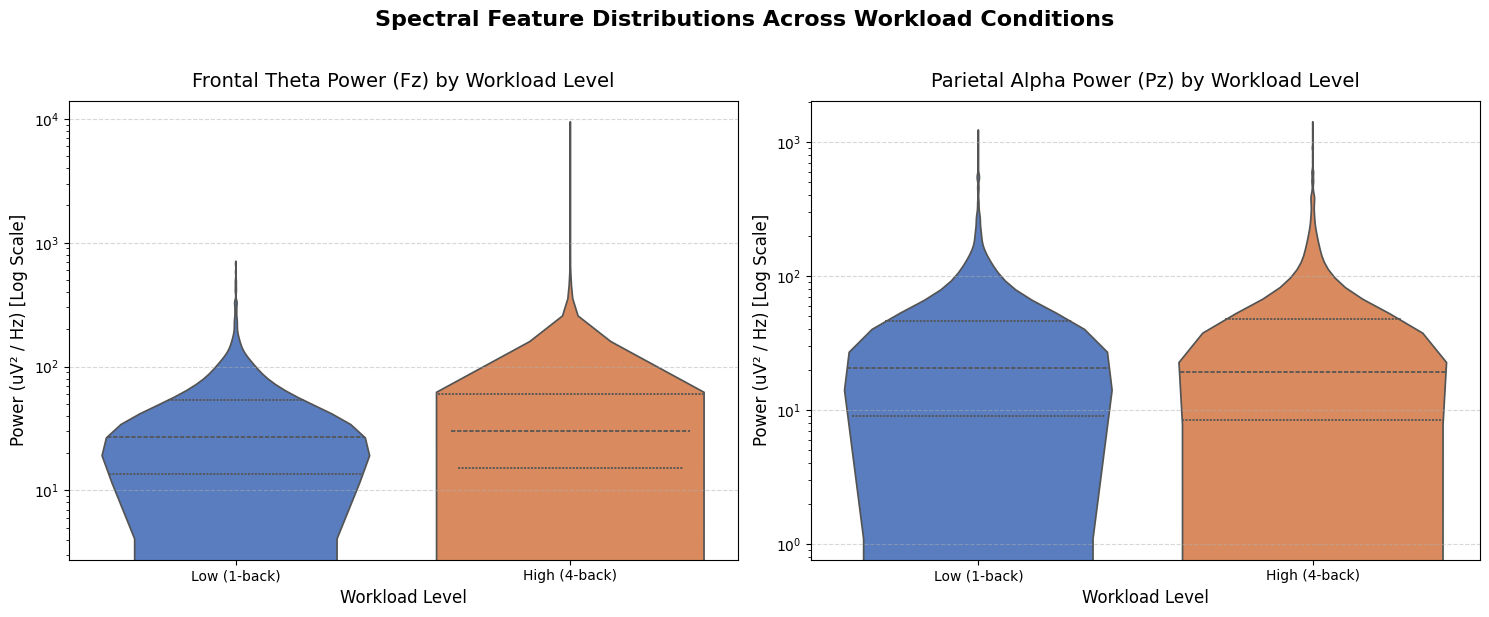

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Map workload numeric classes to human-readable names for plotting
plot_df = binary_df.copy()
plot_df['Workload Level'] = plot_df['nback_level'].map({1: 'Low (1-back)', 4: 'High (4-back)'})

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Frontal Theta Power Distribution
sns.violinplot(
    data=plot_df, x='Workload Level', y='theta_power', ax=axes[0],
    palette='muted', hue='Workload Level', legend=False, inner='quartile'
)
axes[0].set_title('Frontal Theta Power (Fz) by Workload Level', fontsize=14, pad=10)
axes[0].set_ylabel('Power (uV² / Hz)', fontsize=12)
axes[0].set_xlabel('Workload Level', fontsize=12)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# 2. Parietal Alpha Power Distribution
sns.violinplot(
    data=plot_df, x='Workload Level', y='alpha_power', ax=axes[1],
    palette='muted', hue='Workload Level', legend=False, inner='quartile'
)
axes[1].set_title('Parietal Alpha Power (Pz) by Workload Level', fontsize=14, pad=10)
axes[1].set_ylabel('Power (uV² / Hz)', fontsize=12)
axes[1].set_xlabel('Workload Level', fontsize=12)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

# We use a log scale for y-axis if the power ranges are highly skewed or contain large outliers
axes[0].set_yscale('log')
axes[1].set_yscale('log')
axes[0].set_ylabel('Power (uV² / Hz) [Log Scale]', fontsize=12)
axes[1].set_ylabel('Power (uV² / Hz) [Log Scale]', fontsize=12)

plt.suptitle('Spectral Feature Distributions Across Workload Conditions', fontsize=16, weight='bold', y=1.02)
plt.tight_layout()
plt.show()

--- Balanced Classifier Detailed Classification Report ---
               precision    recall  f1-score   support

 Low (1-back)       0.39      0.95      0.55       783
High (4-back)       0.66      0.06      0.11      1252

     accuracy                           0.40      2035
    macro avg       0.52      0.51      0.33      2035
 weighted avg       0.55      0.40      0.28      2035



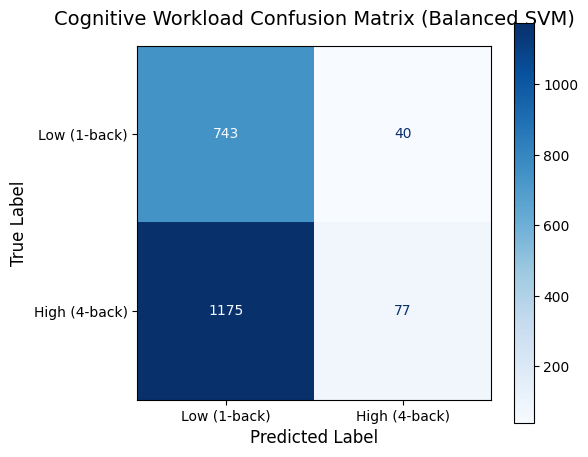

In [26]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Re-build the pipeline with class_weight='balanced' to handle the imbalance
clf_pipeline_balanced = make_pipeline(StandardScaler(), SVC(kernel='linear', C=1.0, class_weight='balanced'))

# Generate cross-validated predictions
y_pred_balanced = cross_val_predict(clf_pipeline_balanced, X, y, cv=cv)

# Compute confusion matrix
cm_balanced = confusion_matrix(y, y_pred_balanced)

# Print detailed classification report
print("--- Balanced Classifier Detailed Classification Report ---")
print(classification_report(y, y_pred_balanced, target_names=['Low (1-back)', 'High (4-back)']))

# Plot the Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_balanced, display_labels=['Low (1-back)', 'High (4-back)'])
disp.plot(cmap='Blues', values_format='d', ax=ax)

plt.title('Cognitive Workload Confusion Matrix (Balanced SVM)', fontsize=14, pad=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

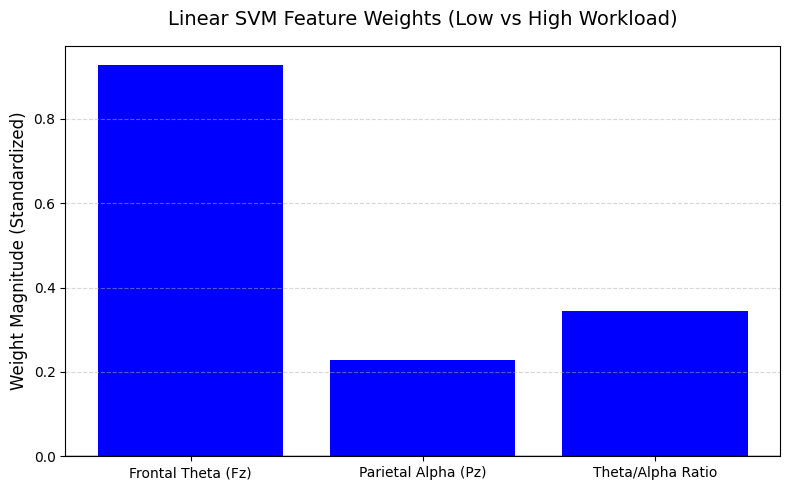

Frontal Theta (Fz) Standardized Weight: 0.9266
Parietal Alpha (Pz) Standardized Weight: 0.2283
Theta/Alpha Ratio Standardized Weight: 0.3455


In [28]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt

# Standardize the features first as we did in our pipeline
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train our balanced SVM classifier
clf = SVC(kernel='linear', class_weight='balanced', random_state=42)
clf.fit(X_scaled, y)

# Extract the weights
weights = clf.coef_[0]
features = ['Frontal Theta (Fz)', 'Parietal Alpha (Pz)', 'Theta/Alpha Ratio']
colors = ['blue' if w > 0 else 'red' for w in weights]

# Plot feature importances
plt.figure(figsize=(8, 5))
plt.bar(features, weights, color=colors)
plt.axhline(0, color='black', linewidth=1)
plt.title("Linear SVM Feature Weights (Low vs High Workload)", fontsize=14, pad=15)
plt.ylabel("Weight Magnitude (Standardized)", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Print exact values
for f, w in zip(features, weights):
    print(f"{f} Standardized Weight: {w:.4f}")